# Multi-Sheet Baseline Models: Boro Rice Production

This notebook combines information from three relevant sheets in the Excel workbook:

- **Table V:** Production and area of major agricultural commodities
- **Table VIB:** Average prices of selected commodities, including Aman rice
- **Table IB:** Annual inflation and exchange-rate indicators

**Target:** Boro Rice Production  
**Baseline models:** Linear Regression, Decision Tree Regressor, and K-Nearest Neighbors (KNN) Regressor

The notebook uses basic EDA, preprocessing, and three simple baseline models only.


## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score


## 2. Load the Workbook

In [2]:
file_path = "/content/Apr26 (For Shounok 16.07.2026).xlsx"

excel_file = pd.ExcelFile(file_path)

print("Number of sheets:", len(excel_file.sheet_names))
print(excel_file.sheet_names)


Number of sheets: 45
['Cover Page', 'Contents', 'Table IA', 'Table IB', 'TableIIA', 'TableIIB', 'TableIIC ', 'Table IID', 'Table IIE', 'Table IIF', 'Table IIG', 'Table III A', 'Table IIIB', 'Table IV', 'Table V', 'Table VIA', 'Table VIB', 'Table VII', 'Table VIII', 'TableIXA', 'TableIXB', 'TableIXC', 'TableIXD', 'TableX', 'TableXI', 'Table XIIA', 'Table XIIB', 'TableXIII', 'Table XIV', 'TableXV', 'TableXVI', 'Table XVII', 'Table XVIII', 'TableXIX', 'TableXX', 'TableXXI', 'Table XXII', 'Table XXIII', 'Table XXIV', 'Table XXV', 'Table XXVI', 'Table XXVII', 'Table XXVIII', 'Table XXIX', 'Appendix- Weights & Measures']


## 3. Load the Three Relevant Sheets

In [3]:
agriculture_raw = pd.read_excel(file_path, sheet_name="Table V", header=None)
price_raw = pd.read_excel(file_path, sheet_name="Table VIB", header=None)
macro_raw = pd.read_excel(file_path, sheet_name="Table IB", header=None)

print("Table V shape:", agriculture_raw.shape)
print("Table VIB shape:", price_raw.shape)
print("Table IB shape:", macro_raw.shape)


Table V shape: (42, 28)
Table VIB shape: (232, 9)
Table IB shape: (268, 16)


## 4. Preview the Source Sheets

In [4]:
print("Table V: Agricultural production")
display(agriculture_raw.head(10))

print("Table VIB: Commodity prices")
display(price_raw.head(10))

print("Table IB: Economic indicators")
display(macro_raw.head(10))


Table V: Agricultural production


,0,1,2,3,4,5,6,7,8,9,...,18,19,20,21,22,23,24,25,26,27
0,PRODUCTION OF MAJOR,NaN,NaN,NaN,NaN,NaN,NaN,AGRICULTURAL COMMODITIES,NaN,NaN,...,NaN,NaN,NaN,AGRICULTURAL COMMODITIES,NaN,NaN,NaN,NaN,TABLE-V (Concld.),NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Period,Aus Rice,NaN,Aman Rice,NaN,Boro Rice,NaN,Wheat,NaN,Sugar Cane,...,NaN,Tobacco,NaN,Tea,NaN,Jute,NaN,Cotton,NaN,Period
3,NaN,Production (in '000' Metric Tons),Area (in '000' acres),Production (in '000' Metric Tons),Area (in '000' acres),Production (in '000' Metric Tons),Area (in '000' acres),Production (in '000' Metric Tons),Area (in '000' acres),Production (in '000' Metric Tons),...,Area (in '000' acres),Production (in '000' Metric Tons),Area (in '000' acres),Production (in '000' Metric Tons),Area (in '000' acres),Production (in '000' Metric Tons),Area (in '000' acres),Production (in '000' Metric Tons),Area (in '000' acres),NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,1994-95,1791,4111,8509,13824,6538,6582,1245,1580,7446,...,512,38,89,52,118,964,1383,13,86,1994-95
7,1995-96,1676,3840,8790,13953,7221,6804,1369,1732,7165,...,509,39,90,48,119,739,1133,13,86,1995-96
8,1996-97,1871,3935,9552,14399,7460,6876,1454,1749,7520,...,510,38,86,53,119,883,1253,14,91,1996-97
9,1997-98,1875,3868,8850,14353,8137,7138,1803,1988,7379,...,508,37,81,51,120,1057,1427,14,86,1997-98


Table VIB: Commodity prices


,0,1,2,3,4,5,6,7,8
0,AVERAGE PRICES OF SELECTED COMMODITIES ...,NaN,NaN,NaN,NaN,NaN,NaN,TABLE-VIB,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Period \n(Calendar Year),Months,Market price (f.o.b.) of Raw Jute of Narayangonj,NaN,Retail Market Price of Dhaka City,NaN,Export of Tea (Average Qu...,Hides & Skins (wholesale),NaN
3,NaN,NaN,White Middle (Kutcha bales) ...,Bangla white A (Pucca bales) (Tk per 182.25...,Aman Rice (Medium) ...,Gold (Guinea) (Tk per 10 gms.),NaN,Cow Hides Raw (Tk ...,Goat Skins (Tk per p...
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,1,2,3,4,5,6,7
7,1993,NaN,1048,2731,12,5352,49,937,118
8,1994,NaN,1269,3217,14,5744,45,1132,127
9,1995,NaN,1350,3364,16,5838,47,1176,125


Table IB: Economic indicators


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
0,NaN,NaN,NaN,NaN,NaN,NaN,SELECTED ECONOMIC,NaN,NaN,NaN,INDICATORS,NaN,NaN,NaN,NaN,TABLE-IB
1,NaN,NaN,NaN,NaN,NaN,NaN,"( Inflation, Production Index, Foreign Trade,",NaN,NaN,NaN,Forex Reserves & Exchange Rate),NaN,NaN,NaN,NaN,NaN
2,Period,Months,Rate of Inflation in Bangladesh Measured by ...,NaN,NaN,NaN,Index of Industrial Production,NaN,NaN,NaN,Foreign Trade (Million US $),NaN,Foreign Exchange Reserves,NaN,Weighted Average Exchange Rate,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,"Index of Manufacturing, Mining & Electricity",NaN,NaN,NaN,Foreign Trade (during the period),NaN,(Million US $),NaN,Tk/US Dollar,NaN
4,NaN,NaN,Point- to- Point (Base: 2021-22=100),Point- to- Point (Base: 2005-06=100),12- Month Average (Base: 2021-22=100),12- Month Average (Base: 2005-06=100),Manufacturing,Mining,Electricity,Total Industries,Exports (Shipment),Import (Shipment),Foreign Exchange Reserves,Foreign Exchange Reserves (as per BPM6 ),Period Average,End Period
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,1,2,3,4,5,6,7,8,9,10,11,12,13,14
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,1994-95,NaN,…,…,…,…,1519,1392,163,83,176,3472.5,5834,3069.6,…,…
9,1995-96,NaN,…,…,…,…,1606,1459,174,79,190,3882.4,6931,2038.6,…,…


# Data Preprocessing

## 5. Clean Table V: Agricultural Production and Area

In [5]:
agriculture = agriculture_raw.iloc[:, [
    0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 23
]].copy()

agriculture.columns = [
    "Period",
    "Aus_Production",
    "Aus_Area",
    "Aman_Production",
    "Aman_Area",
    "Boro_Production",
    "Boro_Area",
    "Wheat_Production",
    "Wheat_Area",
    "Sugarcane_Production",
    "Sugarcane_Area",
    "RapeMustard_Production",
    "RapeMustard_Area",
    "Jute_Production"
]

agriculture = agriculture[
    agriculture["Period"].astype(str).str.strip().str.match(r"^\d{4}-\d{2}$")
].copy()

agriculture.reset_index(drop=True, inplace=True)

agriculture.head()


,Period,Aus_Production,Aus_Area,Aman_Production,Aman_Area,Boro_Production,Boro_Area,Wheat_Production,Wheat_Area,Sugarcane_Production,Sugarcane_Area,RapeMustard_Production,RapeMustard_Area,Jute_Production
0,1994-95,1791,4111,8509,13824,6538,6582,1245,1580,7446,445,245,833,964
1,1995-96,1676,3840,8790,13953,7221,6804,1369,1732,7165,431,246,830,739
2,1996-97,1871,3935,9552,14399,7460,6876,1454,1749,7520,434,249,831,883
3,1997-98,1875,3868,8850,14353,8137,7138,1803,1988,7379,433,254,849,1057
4,1998-99,1617,3519,7736,12762,10552,8715,1988,2180,6951,430,253,850,812


## 6. Convert Agricultural Columns to Numbers

In [6]:
agriculture_numeric_columns = agriculture.columns[1:]

for column in agriculture_numeric_columns:
    agriculture[column] = pd.to_numeric(
        agriculture[column].astype(str).str.replace("\xa0", "").str.replace(",", ""),
        errors="coerce"
    )

agriculture["End_Year"] = agriculture["Period"].str[:4].astype(int) + 1

print("Agricultural records:", agriculture.shape[0])
display(agriculture.head())


Agricultural records: 30


,Period,Aus_Production,Aus_Area,Aman_Production,Aman_Area,Boro_Production,Boro_Area,Wheat_Production,Wheat_Area,Sugarcane_Production,Sugarcane_Area,RapeMustard_Production,RapeMustard_Area,Jute_Production,End_Year
0,1994-95,1791,4111,8509,13824,6538,6582,1245,1580,7446,445,245,833,964,1995
1,1995-96,1676,3840,8790,13953,7221,6804,1369,1732,7165,431,246,830,739,1996
2,1996-97,1871,3935,9552,14399,7460,6876,1454,1749,7520,434,249,831,883,1997
3,1997-98,1875,3868,8850,14353,8137,7138,1803,1988,7379,433,254,849,1057,1998
4,1998-99,1617,3519,7736,12762,10552,8715,1988,2180,6951,430,253,850,812,1999


`End_Year` converts a fiscal period such as `2003-04` into `2004`. It lets us merge Table V with the calendar-year prices in Table VIB.


## 7. Clean Table VIB: Annual Commodity Prices

In [7]:
price_data = price_raw.iloc[:, [0, 1, 4]].copy()

price_data.columns = [
    "Calendar_Year",
    "Month",
    "Aman_Rice_Price"
]

price_data = price_data[
    price_data["Calendar_Year"].astype(str).str.strip().str.match(r"^\d{4}$")
    & price_data["Month"].isna()
].copy()

price_data["Calendar_Year"] = pd.to_numeric(
    price_data["Calendar_Year"],
    errors="coerce"
)

price_data["Aman_Rice_Price"] = pd.to_numeric(
    price_data["Aman_Rice_Price"].astype(str).str.replace("\xa0", "").str.replace(",", ""),
    errors="coerce"
)

price_data = price_data[["Calendar_Year", "Aman_Rice_Price"]]

print("Annual price records:", price_data.shape[0])
display(price_data.head())


Annual price records: 33


,Calendar_Year,Aman_Rice_Price
7,1993,12.0
8,1994,14.0
9,1995,16.0
10,1996,15.0
11,1997,13.0


## 8. Clean Table IB: Annual Inflation and Exchange Rate

In [8]:
macro_data = macro_raw.iloc[:, [0, 1, 4, 5, 14]].copy()

macro_data.columns = [
    "Period",
    "Month",
    "Inflation_12M_New_Base",
    "Inflation_12M_Old_Base",
    "Exchange_Rate_Average"
]

macro_data = macro_data[
    macro_data["Period"].astype(str).str.strip().str.match(r"^\d{4}-\d{2}$")
    & macro_data["Month"].isna()
].copy()

macro_data = macro_data.drop_duplicates(subset="Period", keep="first")

for column in [
    "Inflation_12M_New_Base",
    "Inflation_12M_Old_Base",
    "Exchange_Rate_Average"
]:
    macro_data[column] = pd.to_numeric(
        macro_data[column].astype(str).str.replace("\xa0", "").str.replace(",", ""),
        errors="coerce"
    )

macro_data["Inflation_12M_Average"] = macro_data[
    "Inflation_12M_New_Base"
].fillna(
    macro_data["Inflation_12M_Old_Base"]
)

macro_data = macro_data[
    ["Period", "Inflation_12M_Average", "Exchange_Rate_Average"]
]

print("Annual macroeconomic records:", macro_data.shape[0])
display(macro_data.head())


Annual macroeconomic records: 30


,Period,Inflation_12M_Average,Exchange_Rate_Average
8,1994-95,NaN,NaN
9,1995-96,NaN,NaN
10,1996-97,3.96,NaN
11,1997-98,8.66,NaN
12,1998-99,7.06,NaN


## 9. Merge the Three Cleaned Sheets

In [9]:
df = agriculture.merge(
    price_data,
    left_on="End_Year",
    right_on="Calendar_Year",
    how="inner"
)

df = df.merge(
    macro_data,
    on="Period",
    how="inner"
)

df = df.dropna().reset_index(drop=True)

print("Final merged dataset shape:", df.shape)
display(df.head())


Final merged dataset shape: (21, 19)


,Period,Aus_Production,Aus_Area,Aman_Production,Aman_Area,Boro_Production,Boro_Area,Wheat_Production,Wheat_Area,Sugarcane_Production,Sugarcane_Area,RapeMustard_Production,RapeMustard_Area,Jute_Production,End_Year,Calendar_Year,Aman_Rice_Price,Inflation_12M_Average,Exchange_Rate_Average
0,2003-04,1832,2971,11521,14030,12837,9745,1253,1586,6484,404,211,690,794,2004,2004,15.750000,5.83,58.9027
1,2004-05,1500,2532,9820,13047,13837,10042,976,1380,6423,388,191,597,1035,2005,2005,21.600000,6.48,61.4492
2,2005-06,1754,2556,10810,13416,13975,10047,735,1184,5511,377,183,536,838,2006,2006,25.344286,7.16,67.1600
3,2006-07,1512,2238,10841,13382,14965,10522,737,988,5770,371,189,520,879,2007,2007,29.182500,7.20,69.0600
4,2007-08,1507,2270,9662,12474,17762,11386,844,958,4984,320,228,577,832,2008,2008,42.047500,9.94,68.6103


The final dataset contains only years present in all three sheets. This ensures that every row has agricultural, price, and macroeconomic information.


## 10. Check Missing Values

In [10]:
print("Missing values in the final dataset:")
print(df.isnull().sum())


Missing values in the final dataset:
Period                    0
Aus_Production            0
Aus_Area                  0
Aman_Production           0
Aman_Area                 0
Boro_Production           0
Boro_Area                 0
Wheat_Production          0
Wheat_Area                0
Sugarcane_Production      0
Sugarcane_Area            0
RapeMustard_Production    0
RapeMustard_Area          0
Jute_Production           0
End_Year                  0
Calendar_Year             0
Aman_Rice_Price           0
Inflation_12M_Average     0
Exchange_Rate_Average     0
dtype: int64


## 11. Descriptive Statistics

In [11]:
df.describe()


,Aus_Production,Aus_Area,Aman_Production,Aman_Area,Boro_Production,Boro_Area,Wheat_Production,Wheat_Area,Sugarcane_Production,Sugarcane_Area,RapeMustard_Production,RapeMustard_Area,Jute_Production,End_Year,Calendar_Year,Aman_Rice_Price,Inflation_12M_Average,Exchange_Rate_Average
count,21.000000,21.000000,21.000000,21.000000,21.000000,21.000000,21.000000,21.000000,21.000000,21.000000,21.000000,21.000000,21.000000,21.000000,21.000000,21.000000,21.000000,21.000000
mean,2276.619048,2627.666667,12954.380952,13737.000000,18154.238095,11451.857143,1070.714286,988.238095,4402.380952,268.380952,316.571429,723.619048,1273.333333,2014.000000,2014.000000,38.781910,7.107505,78.682502
std,541.455398,228.182675,1801.430195,401.874732,2312.024068,722.316571,191.900272,204.242480,1066.359436,72.875563,117.298155,147.174548,303.877826,6.204837,6.204837,10.673494,1.592952,13.643737
min,1500.000000,2238.000000,9662.000000,12474.000000,12837.000000,9745.000000,735.000000,770.000000,2934.000000,167.000000,183.000000,520.000000,794.000000,2004.000000,2004.000000,15.750000,5.440000,58.902700
25%,1832.000000,2532.000000,11613.000000,13665.000000,17809.000000,11386.000000,972.000000,821.000000,3639.000000,213.000000,228.000000,608.000000,916.000000,2009.000000,2009.000000,35.166667,5.830000,69.060000
50%,2289.000000,2602.000000,13023.000000,13814.000000,18778.000000,11788.000000,1085.000000,958.000000,4469.000000,265.000000,296.000000,724.000000,1370.000000,2014.000000,2014.000000,37.666667,6.660000,78.268600
75%,2755.000000,2731.000000,14055.000000,13993.000000,19576.000000,11886.000000,1253.000000,1062.000000,4984.000000,312.000000,362.000000,803.000000,1511.000000,2019.000000,2019.000000,44.666667,7.350000,84.020800
max,3285.000000,3225.000000,16656.000000,14210.000000,21068.000000,12053.000000,1348.000000,1586.000000,6484.000000,404.000000,638.000000,1144.000000,1725.000000,2024.000000,2024.000000,58.000000,10.620000,117.978700


# Exploratory Data Analysis (EDA)

## 12. Boro Rice Production Over Time

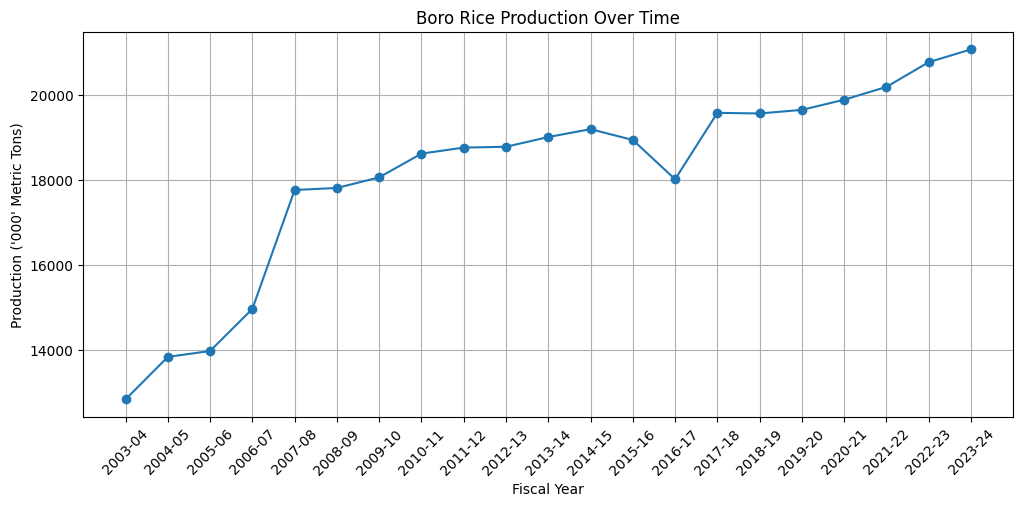

In [12]:
plt.figure(figsize=(12, 5))

plt.plot(
    df["Period"],
    df["Boro_Production"],
    marker="o"
)

plt.title("Boro Rice Production Over Time")
plt.xlabel("Fiscal Year")
plt.ylabel("Production ('000' Metric Tons)")
plt.xticks(rotation=45)
plt.grid()
plt.show()


## 13. Aman Rice Price Over Time (from Table VIB)

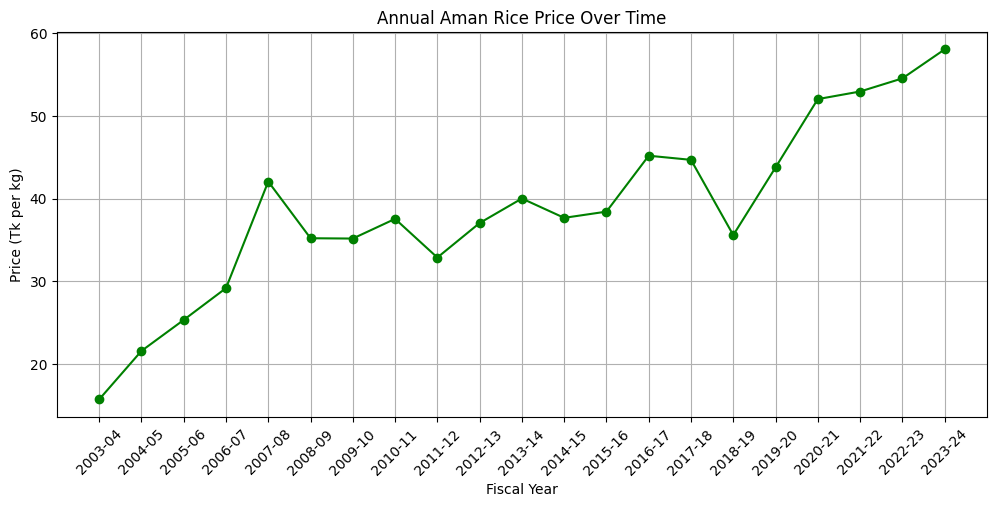

In [13]:
plt.figure(figsize=(12, 5))

plt.plot(
    df["Period"],
    df["Aman_Rice_Price"],
    marker="o",
    color="green"
)

plt.title("Annual Aman Rice Price Over Time")
plt.xlabel("Fiscal Year")
plt.ylabel("Price (Tk per kg)")
plt.xticks(rotation=45)
plt.grid()
plt.show()


## 14. Distribution of Boro Rice Production

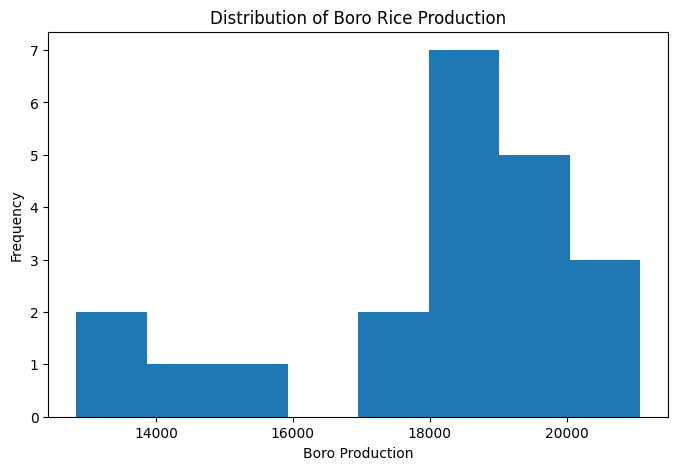

In [14]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["Boro_Production"],
    bins=8
)

plt.title("Distribution of Boro Rice Production")
plt.xlabel("Boro Production")
plt.ylabel("Frequency")
plt.show()


## 15. Boro Area vs Boro Production

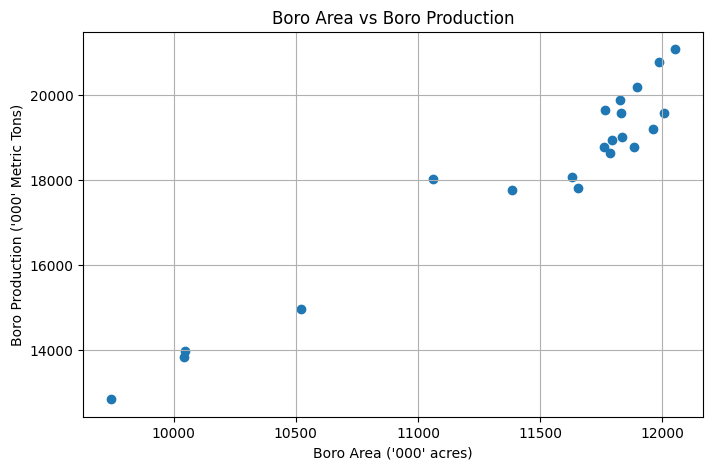

In [15]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Boro_Area"],
    df["Boro_Production"]
)

plt.title("Boro Area vs Boro Production")
plt.xlabel("Boro Area ('000' acres)")
plt.ylabel("Boro Production ('000' Metric Tons)")
plt.grid()
plt.show()


## 16. Aman Rice Price vs Boro Production

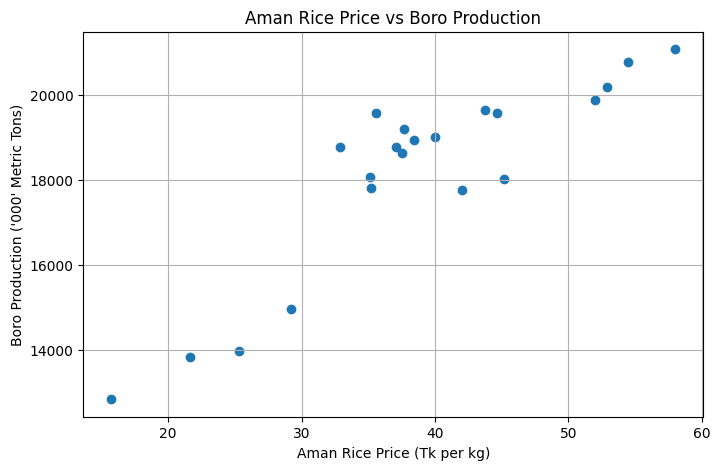

In [16]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Aman_Rice_Price"],
    df["Boro_Production"]
)

plt.title("Aman Rice Price vs Boro Production")
plt.xlabel("Aman Rice Price (Tk per kg)")
plt.ylabel("Boro Production ('000' Metric Tons)")
plt.grid()
plt.show()


## 17. Inflation vs Boro Production

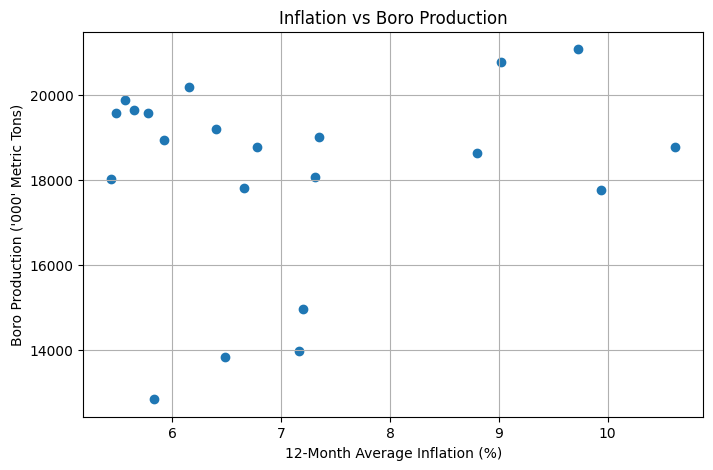

In [17]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Inflation_12M_Average"],
    df["Boro_Production"]
)

plt.title("Inflation vs Boro Production")
plt.xlabel("12-Month Average Inflation (%)")
plt.ylabel("Boro Production ('000' Metric Tons)")
plt.grid()
plt.show()


## 18. Correlation Matrix

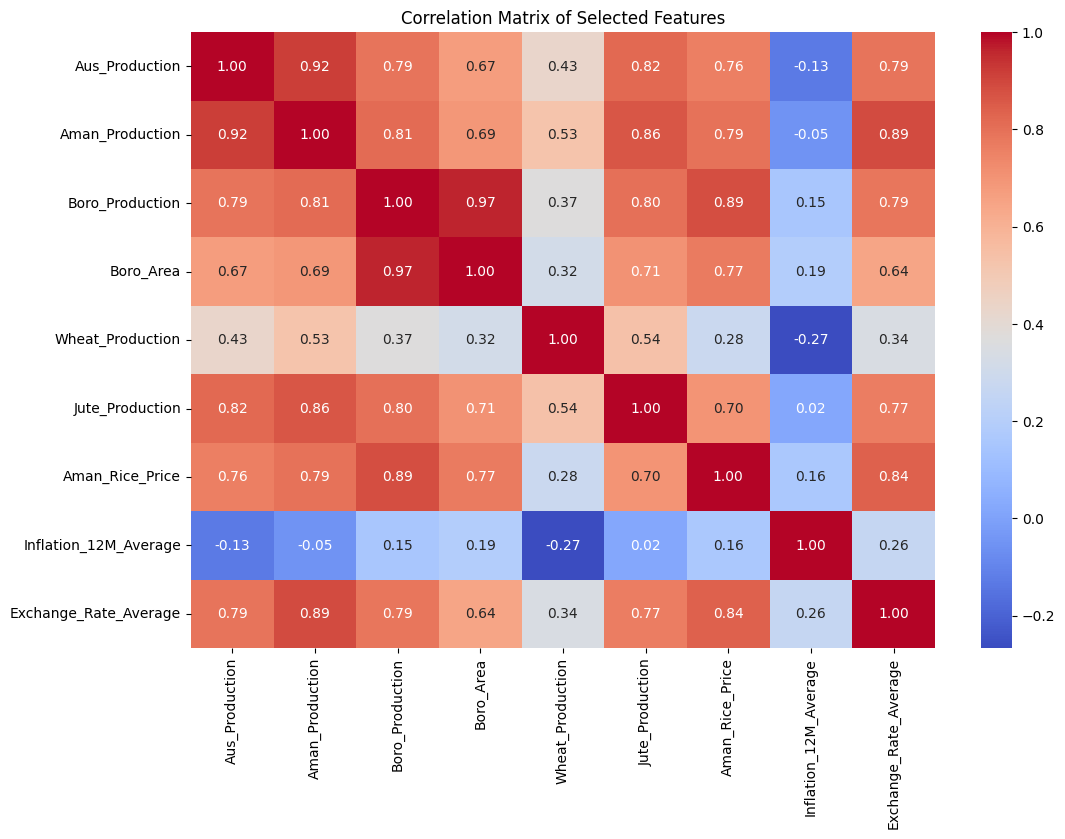

In [18]:
correlation_columns = [
    "Aus_Production",
    "Aman_Production",
    "Boro_Production",
    "Boro_Area",
    "Wheat_Production",
    "Jute_Production",
    "Aman_Rice_Price",
    "Inflation_12M_Average",
    "Exchange_Rate_Average"
]

plt.figure(figsize=(12, 8))

correlation = df[correlation_columns].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Selected Features")
plt.show()


# Baseline Model Preparation

## 19. Select Features and Target

In [19]:
feature_columns = [
    "Boro_Area",
    "Aus_Production",
    "Aman_Production",
    "Wheat_Production",
    "Sugarcane_Production",
    "RapeMustard_Production",
    "Jute_Production",
    "Aman_Rice_Price",
    "Inflation_12M_Average",
    "Exchange_Rate_Average"
]

X = df[feature_columns]
y = df["Boro_Production"]

print("Features:")
display(X.head())

print("\nTarget:")
display(y.head())


Features:


,Boro_Area,Aus_Production,Aman_Production,Wheat_Production,Sugarcane_Production,RapeMustard_Production,Jute_Production,Aman_Rice_Price,Inflation_12M_Average,Exchange_Rate_Average
0,9745,1832,11521,1253,6484,211,794,15.750000,5.83,58.9027
1,10042,1500,9820,976,6423,191,1035,21.600000,6.48,61.4492
2,10047,1754,10810,735,5511,183,838,25.344286,7.16,67.1600
3,10522,1512,10841,737,5770,189,879,29.182500,7.20,69.0600
4,11386,1507,9662,844,4984,228,832,42.047500,9.94,68.6103



Target:


,Boro_Production
0,12837
1,13837
2,13975
3,14965
4,17762


## 20. Train-Test Split

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (16, 10)
Testing data: (5, 10)


## 21. Feature Scaling

In [21]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


Scaling is used for KNN because KNN calculates distances between data points.

# Baseline Model 1: Linear Regression

## 22. Train Linear Regression

In [22]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_prediction = linear_model.predict(X_test)


## 23. Evaluate Linear Regression

In [23]:
linear_mae = mean_absolute_error(y_test, linear_prediction)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_prediction))
linear_r2 = r2_score(y_test, linear_prediction)

print("Linear Regression")
print("----------------------")
print("MAE:", linear_mae)
print("RMSE:", linear_rmse)
print("R2 Score:", linear_r2)


Linear Regression
----------------------
MAE: 184.207996264501
RMSE: 213.4333214970538
R2 Score: 0.9949729027277812


# Baseline Model 2: Decision Tree Regressor

## 24. Train Decision Tree

In [24]:
tree_model = DecisionTreeRegressor(random_state=42)

tree_model.fit(X_train, y_train)

tree_prediction = tree_model.predict(X_test)


## 25. Evaluate Decision Tree

In [25]:
tree_mae = mean_absolute_error(y_test, tree_prediction)
tree_rmse = np.sqrt(mean_squared_error(y_test, tree_prediction))
tree_r2 = r2_score(y_test, tree_prediction)

print("Decision Tree")
print("----------------------")
print("MAE:", tree_mae)
print("RMSE:", tree_rmse)
print("R2 Score:", tree_r2)


Decision Tree
----------------------
MAE: 544.8
RMSE: 731.9040920776437
R2 Score: 0.940884523672305


# Baseline Model 3: K-Nearest Neighbors (KNN) Regressor

## 26. Train KNN

In [26]:
knn_model = KNeighborsRegressor(n_neighbors=3)

knn_model.fit(X_train_scaled, y_train)

knn_prediction = knn_model.predict(X_test_scaled)


## 27. Evaluate KNN

In [27]:
knn_mae = mean_absolute_error(y_test, knn_prediction)
knn_rmse = np.sqrt(mean_squared_error(y_test, knn_prediction))
knn_r2 = r2_score(y_test, knn_prediction)

print("KNN Regression")
print("----------------------")
print("MAE:", knn_mae)
print("RMSE:", knn_rmse)
print("R2 Score:", knn_r2)


KNN Regression
----------------------
MAE: 971.5333333333335
RMSE: 1459.8595594554065
R2 Score: 0.7648120867359228


# Model Comparison

## 28. Create a Model Comparison Table

In [28]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "KNN"
    ],
    "MAE": [
        linear_mae,
        tree_mae,
        knn_mae
    ],
    "RMSE": [
        linear_rmse,
        tree_rmse,
        knn_rmse
    ],
    "R2 Score": [
        linear_r2,
        tree_r2,
        knn_r2
    ]
})

results


,Model,MAE,RMSE,R2 Score
0,Linear Regression,184.207996,213.433321,0.994973
1,Decision Tree,544.800000,731.904092,0.940885
2,KNN,971.533333,1459.859559,0.764812


## 29. Compare R² Scores Visually

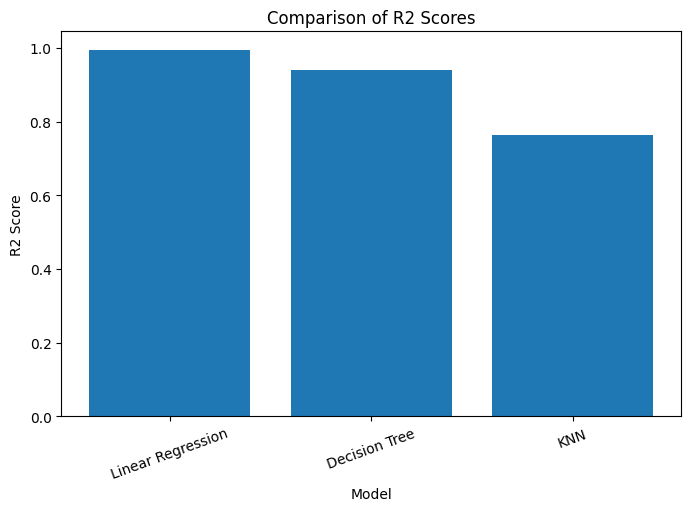

In [29]:
plt.figure(figsize=(8, 5))

plt.bar(
    results["Model"],
    results["R2 Score"]
)

plt.title("Comparison of R2 Scores")
plt.xlabel("Model")
plt.ylabel("R2 Score")
plt.xticks(rotation=20)
plt.show()


## 30. Actual vs Predicted Boro Production

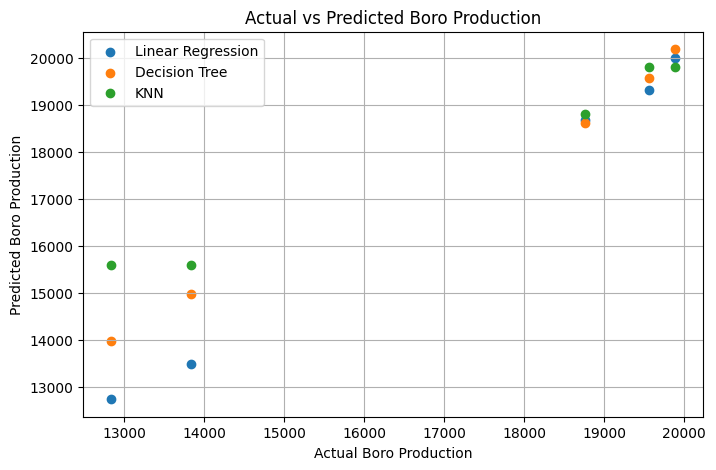

In [30]:
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    linear_prediction,
    label="Linear Regression"
)

plt.scatter(
    y_test,
    tree_prediction,
    label="Decision Tree"
)

plt.scatter(
    y_test,
    knn_prediction,
    label="KNN"
)

plt.xlabel("Actual Boro Production")
plt.ylabel("Predicted Boro Production")
plt.title("Actual vs Predicted Boro Production")
plt.legend()
plt.grid()
plt.show()


## 31. Final Model Performance

In [31]:
print("Final Model Performance")
print("========================")

for i in range(len(results)):
    print("\nModel:", results.loc[i, "Model"])
    print("MAE:", round(results.loc[i, "MAE"], 2))
    print("RMSE:", round(results.loc[i, "RMSE"], 2))
    print("R2 Score:", round(results.loc[i, "R2 Score"], 2))


Final Model Performance

Model: Linear Regression
MAE: 184.21
RMSE: 213.43
R2 Score: 0.99

Model: Decision Tree
MAE: 544.8
RMSE: 731.9
R2 Score: 0.94

Model: KNN
MAE: 971.53
RMSE: 1459.86
R2 Score: 0.76


## 32. Find the Best Baseline Model

In [32]:
best_model = results.loc[results["R2 Score"].idxmax()]

print("Best Baseline Model:")
print(best_model["Model"])

print("\nR2 Score:", best_model["R2 Score"])


Best Baseline Model:
Linear Regression

R2 Score: 0.9949729027277812


# Deliverables Covered

- Multi-sheet data loading and merging
- EDA with visuals from agricultural, price, and macroeconomic data
- Dataset preprocessing and missing-value handling
- Exactly three basic baseline models: Linear Regression, Decision Tree Regressor, and KNN Regressor
- Model evaluation using MAE, RMSE, and R²

The merged dataset contains a limited number of annual observations. These results should be interpreted as baseline benchmarks.
